## **Federated Learning Across Hospitals: A Comparative Study of Aggregation Methods Under Real Domain Shift Using CNNs on Multi-Hospital Histopathology Data**

# Submission 2: Pretrained CNNs, with and without fine-tuning

# Group Information
Name: Sayka Ferdous

ID: 2023-3-60-110

Name: Asrafun Nahar Raisa

ID: 2023-3-60-228

Name: Khaleda Sultana Jamie

ID: 2023-3-60-397

Name: Tahira Tasnim

ID: 2023-3-60-267

### Overview

**Task:** Camelyon17-WILDS (same dataset as Submission 1), binary tumor / no-tumor classification of 96×96 lymph-node patches.

| Role | Hospital | Purpose |
|---|---|---|
| Train | 0, 3, 4 | fit the models (future federated clients) |
| Validation | 1 | select the best epoch |
| Test | 2 | never seen in training; measures generalisation to a new hospital |

**Models:** ImageNet-pretrained ResNet-50, DenseNet-121 and EfficientNet-B0, each trained for 30 epochs in two modes:
1. **Without fine-tuning:** backbone frozen (including BatchNorm statistics), only the new 2-class head is trained.
2. **With fine-tuning:** all layers trained (backbone lr 1e-4, head lr 1e-3).

**Subset:** stratified random subset that keeps hospital and class proportions (sizes in the config cell).

**Against overfitting/underfitting:** augmentation, dropout 0.3, label smoothing 0.1, AdamW weight decay, cosine learning-rate decay, and restoring the best-validation-epoch weights before testing. A diagnostics cell near the end checks every run.

**Reported for every run:** accuracy, precision, recall, F1 (per class and macro), AUC, accuracy/loss curves, test confusion matrix, training and testing time.

### 1. Setup and configuration

In [8]:
import os, json, time, copy, random, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import models
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, roc_auc_score)
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")


SEED        = 42
EPOCHS      = 30
BATCH_SIZE  = 128
IMG_SIZE    = 96
TRAIN_N     = 20000
VAL_N       = 6000
TEST_N      = 20000
PRETRAINED  = True
MODELS      = ["resnet50", "densenet121", "efficientnet_b0"]
CLASS_NAMES = ["No tumor", "Tumor"]


device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

WORK_DIR = "/content/cse366_submission2"
RESULTS_DIR = f"{WORK_DIR}/results"; CACHE_DIR = f"{WORK_DIR}/cache"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - switch Runtime > Change runtime type > GPU")

torch 2.11.0+cu130 | device: cuda | Tesla T4


### 2. Download Camelyon17-WILDS

In [9]:
if not os.path.exists("/content/data/camelyon17_v1.0/metadata.csv"):
    !rm -rf /content/data/camelyon17_v1.0
    !mkdir -p /content/data/camelyon17_v1.0
    !wget --no-check-certificate -O /content/data/camelyon17_v1.0/archive.tar.gz "https://worksheets.codalab.org/rest/bundles/0xe45e15f39fb54e9d9e919556af67aabe/contents/blob/"
    !tar -xzf /content/data/camelyon17_v1.0/archive.tar.gz -C /content/data/camelyon17_v1.0
    !rm /content/data/camelyon17_v1.0/archive.tar.gz
else:
    print("Data already downloaded, skipping.")

!pip install -q wilds
from wilds import get_dataset
dataset = get_dataset(dataset="camelyon17", download=False, root_dir="/content/data")
meta = pd.read_csv("/content/data/camelyon17_v1.0/metadata.csv", index_col=0)
print("Loaded:", dataset, "| metadata:", meta.shape)

Data already downloaded, skipping.
Loaded: <wilds.datasets.camelyon17_dataset.Camelyon17Dataset object at 0x7b7b2fa5ef90> | metadata: (455954, 8)


### 3. Build the train / validation / test subsets

Subsets are sampled **within each (hospital, class) group**, so every hospital keeps its original share and every class stays 50/50. Images are decoded once and kept in memory as `uint8` arrays (and cached on disk), so the 30-epoch runs are not limited by PNG decoding.

In [10]:
from concurrent.futures import ThreadPoolExecutor

def stratified_subset(split_name, n):
    idx = np.asarray(dataset.get_subset(split_name).indices)
    df = pd.DataFrame({"idx": idx, "center": meta["center"].values[idx], "tumor": meta["tumor"].values[idx]})
    if n < len(df):
        df = df.groupby(["center", "tumor"], group_keys=False).sample(frac=n / len(df), random_state=SEED)
    return np.random.RandomState(SEED).permutation(df["idx"].values)

def load_images(idx):
    X = np.empty((len(idx), 96, 96, 3), dtype=np.uint8)
    def f(j): X[j] = np.asarray(dataset.get_input(idx[j]).convert("RGB"))
    with ThreadPoolExecutor(16) as ex:
        list(tqdm(ex.map(f, range(len(idx))), total=len(idx), leave=False))
    return X

CACHE_FILE = f"{CACHE_DIR}/subsets_tr{TRAIN_N}_va{VAL_N}_te{TEST_N}_seed{SEED}.npz"
if os.path.exists(CACHE_FILE):
    z = np.load(CACHE_FILE); print("Loaded cached subsets:", CACHE_FILE)
    Xtr_np, ytr_np, ctr = z["Xtr"], z["ytr"], z["ctr"]
    Xva_np, yva_np, cva = z["Xva"], z["yva"], z["cva"]
    Xte_np, yte_np, cte = z["Xte"], z["yte"], z["cte"]
else:
    t0 = time.time(); out = {}
    for key, split, n in [("tr", "train", TRAIN_N), ("va", "val", VAL_N), ("te", "test", TEST_N)]:
        idx = stratified_subset(split, n)
        out["X" + key] = load_images(idx)
        out["y" + key] = meta["tumor"].values[idx].astype(np.int64)
        out["c" + key] = meta["center"].values[idx]
        print(f"{split:5s}: {len(idx):6d} images loaded ({time.time()-t0:.0f}s)")
    np.savez(CACHE_FILE, **out)
    Xtr_np, ytr_np, ctr = out["Xtr"], out["ytr"], out["ctr"]
    Xva_np, yva_np, cva = out["Xva"], out["yva"], out["cva"]
    Xte_np, yte_np, cte = out["Xte"], out["yte"], out["cte"]

summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "hospitals": [sorted(set(ctr)), sorted(set(cva)), sorted(set(cte))],
    "images": [len(ytr_np), len(yva_np), len(yte_np)],
    "no tumor": [(ytr_np == 0).sum(), (yva_np == 0).sum(), (yte_np == 0).sum()],
    "tumor": [(ytr_np == 1).sum(), (yva_np == 1).sum(), (yte_np == 1).sum()],
})
display(summary)
print("Training images per hospital:", {int(h): int(n) for h, n in zip(*np.unique(ctr, return_counts=True))})

  0%|          | 0/20000 [00:00<?, ?it/s]

train:  20000 images loaded (31s)


  0%|          | 0/6000 [00:00<?, ?it/s]

val  :   6000 images loaded (40s)


  0%|          | 0/20000 [00:00<?, ?it/s]

test :  20000 images loaded (65s)


,split,hospitals,images,no tumor,tumor
0,train,"[0, 3, 4]",20000,9989,10011
1,validation,[1],6000,3000,3000
2,test,[2],20000,10000,10000


Training images per hospital: {0: 3533, 3: 7734, 4: 8733}


In [11]:

def to_dev(X): return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(device)
Xtr, Xva, Xte = to_dev(Xtr_np), to_dev(Xva_np), to_dev(Xte_np)
ytr, yva, yte = [torch.from_numpy(y).to(device) for y in (ytr_np, yva_np, yte_np)]
print("Train", tuple(Xtr.shape), "| Val", tuple(Xva.shape), "| Test", tuple(Xte.shape))

Train (20000, 3, 96, 96) | Val (6000, 3, 96, 96) | Test (20000, 3, 96, 96)


### 4. Preprocessing and augmentation (decided in Submission 1)

- **Normalisation:** ImageNet mean/std, because the backbones are ImageNet-pretrained.
- **Augmentation (training only):** random horizontal/vertical flips and 90° rotations (tissue has no fixed orientation), plus brightness, contrast, saturation and a small per-channel colour shift to imitate the stain/scanner differences between hospitals. Validation and test images are only normalised.
- Augmentation runs on the GPU, per sample.

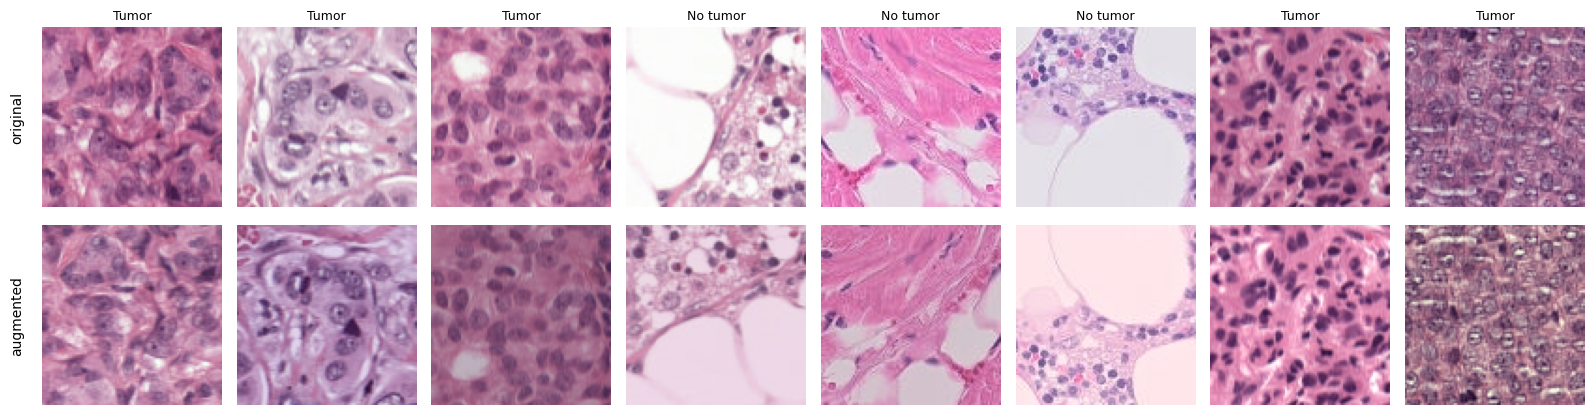

In [12]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def augment(x):
    n, d = x.shape[0], x.device

    m = torch.rand(n, device=d) < 0.5; x = torch.where(m[:, None, None, None], x.flip(3), x)
    m = torch.rand(n, device=d) < 0.5; x = torch.where(m[:, None, None, None], x.flip(2), x)

    k, out = torch.randint(0, 4, (n,), device=d), x.clone()
    for r in (1, 2, 3):
        sel = k == r
        if sel.any(): out[sel] = torch.rot90(x[sel], r, (2, 3))
    x = out

    u = lambda lo, hi: torch.empty(n, 1, 1, 1, device=d).uniform_(lo, hi)
    x = x * u(0.8, 1.2)                                                     # brightness
    mean = x.mean((1, 2, 3), keepdim=True); x = (x - mean) * u(0.8, 1.2) + mean   # contrast
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]; x = (x - gray) * u(0.8, 1.2) + gray  # saturation
    x = x * torch.empty(n, 3, 1, 1, device=d).uniform_(0.93, 1.07)          # per-channel shift (hue/stain)
    return x.clamp(0, 1)

def prep(xb, train=False):
    x = xb.float().div_(255)
    if x.shape[-1] != IMG_SIZE:
        x = F.interpolate(x, size=IMG_SIZE, mode="bilinear", align_corners=False)
    if train: x = augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


idx = torch.arange(8, device=device)
raw = Xtr[idx].float().div(255); aug = augment(raw.clone())
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for j in range(8):
    for r, im in enumerate((raw, aug)):
        ax[r, j].imshow(im[j].permute(1, 2, 0).cpu().numpy()); ax[r, j].axis("off")
    ax[0, j].set_title(CLASS_NAMES[int(ytr[j])], fontsize=9)
ax[0, 0].text(-0.1, 0.5, "original", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.1, 0.5, "augmented", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

### 5. Models and training code

`make_model(name, mode)` loads the ImageNet weights and replaces the classifier with `Dropout(0.3) → Linear(·, 2)`.

- `mode="frozen"` (**without fine-tuning**): every backbone parameter has `requires_grad=False` and the backbone is kept in `eval()` mode, so BatchNorm statistics are also frozen. Only the head learns.
- `mode="finetune"` (**with fine-tuning**): all layers train; the backbone uses a 10× smaller learning rate than the head.

The training loop runs the full 30 epochs, records train/validation loss and accuracy every epoch, and keeps the weights of the best validation epoch. Loss values in the curves are plain cross-entropy (label smoothing is used only for optimisation), so train and validation losses are directly comparable. Training accuracy is measured on the augmented batches during training.

In [13]:
def get_head(m, name):
    return m.fc if name == "resnet50" else m.classifier

def make_model(name, mode):
    P = PRETRAINED
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if P else None)
        in_f = m.fc.in_features
    elif name == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1 if P else None)
        in_f = m.classifier.in_features
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if P else None)
        in_f = m.classifier[1].in_features
    else:
        raise ValueError(name)
    if mode == "frozen":
        for p in m.parameters(): p.requires_grad = False
    head = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, 2))
    if name == "resnet50": m.fc = head
    else: m.classifier = head
    return m

def set_train_mode(model, name, mode):
    if mode == "frozen":
        model.eval()
        get_head(model, name).train()
    else:
        model.train()

@torch.no_grad()
def predict(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out.append(model(prep(X[i:i + bs])).float())
    return torch.cat(out)

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

In [14]:
CFG_SIG = f"e{EPOCHS}_tr{TRAIN_N}_va{VAL_N}_te{TEST_N}_s{IMG_SIZE}_seed{SEED}"

def run_experiment(name, mode):
    tag = f"{name}_{mode}_{CFG_SIG}"
    path = f"{RESULTS_DIR}/{tag}.json"
    if os.path.exists(path):
        print(f"[{tag}] found saved result, skipping training.")
        return json.load(open(path))

    set_seed(SEED)
    model = make_model(name, mode).to(device).to(memory_format=torch.channels_last)
    head_ids = {id(p) for p in get_head(model, name).parameters()}
    head_params = [p for p in model.parameters() if id(p) in head_ids]
    if mode == "frozen":
        groups = [{"params": head_params, "lr": 1e-3}]
    else:
        back = [p for p in model.parameters() if id(p) not in head_ids]
        groups = [{"params": back, "lr": 1e-4}, {"params": head_params, "lr": 1e-3}]
    opt   = torch.optim.AdamW(groups, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    total_p, train_p = count_params(model)

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1, "val_loss": 1e9, "epoch": 0, "state": None}
    n = len(Xtr); steps = n // BATCH_SIZE
    print(f"\n=== {name} | {mode} | params {total_p/1e6:.1f}M (trainable {train_p/1e6:.2f}M) ===")
    sync(); t_fit = time.time()
    for ep in range(1, EPOCHS + 1):
        set_train_mode(model, name, mode)
        perm = torch.randperm(n, device=device)
        run_loss = run_correct = seen = 0
        for s in range(steps):
            b = perm[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]
            x, y = prep(Xtr[b], train=True), ytr[b]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss    += F.cross_entropy(logits.detach().float(), y, reduction="sum").item()
            run_correct += (logits.argmax(1) == y).sum().item(); seen += len(y)
        sched.step()
        vl = predict(model, Xva)
        v_loss = F.cross_entropy(vl, yva).item(); v_acc = (vl.argmax(1) == yva).float().mean().item()
        for k, v in zip(hist, [run_loss / seen, run_correct / seen, v_loss, v_acc]): hist[k].append(v)
        improved = v_acc > best["val_acc"] or (v_acc == best["val_acc"] and v_loss < best["val_loss"])
        if improved:
            best.update(val_acc=v_acc, val_loss=v_loss, epoch=ep,
                        state={k: t.detach().clone() for k, t in model.state_dict().items()})
        print(f"ep {ep:2d}/{EPOCHS} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} "
              f"| val loss {v_loss:.4f} acc {v_acc:.4f}{'  *best' if improved else ''}")
    sync(); train_time = time.time() - t_fit

    model.load_state_dict(best["state"])


    vl = predict(model, Xva); vpred = vl.argmax(1).cpu().numpy()
    v_prf = precision_recall_fscore_support(yva_np, vpred, average="macro", zero_division=0)


    predict(model, Xte[:BATCH_SIZE]); sync(); t0 = time.time()
    logits = predict(model, Xte); sync(); test_time = time.time() - t0
    probs = torch.softmax(logits, 1)[:, 1].cpu().numpy(); pred = logits.argmax(1).cpu().numpy()
    prf = precision_recall_fscore_support(yte_np, pred, average="macro", zero_division=0)

    res = {
        "model": name, "mode": mode, "epochs": EPOCHS, "history": hist,
        "best_epoch": best["epoch"], "params_total": total_p, "params_trainable": train_p,
        "train_time_s": train_time, "test_time_s": test_time, "n_test": int(len(yte_np)),
        "train_acc_at_best": hist["train_acc"][best["epoch"] - 1],
        "val_acc": best["val_acc"], "val_loss": best["val_loss"], "val_f1": float(v_prf[2]),
        "test_acc": float(accuracy_score(yte_np, pred)),
        "test_precision": float(prf[0]), "test_recall": float(prf[1]), "test_f1": float(prf[2]),
        "test_auc": float(roc_auc_score(yte_np, probs)),
        "confusion_matrix": confusion_matrix(yte_np, pred).tolist(),
        "report_text": classification_report(yte_np, pred, target_names=CLASS_NAMES, digits=4),
        "report_dict": classification_report(yte_np, pred, target_names=CLASS_NAMES, output_dict=True),
    }
    json.dump(res, open(path, "w"))
    del model, opt, best; torch.cuda.empty_cache()
    return res

MODE_LABEL = {"frozen": "WITHOUT fine-tuning (frozen backbone)", "finetune": "WITH fine-tuning (all layers)"}

def show_run(res):
    h, be = res["history"], res["best_epoch"]
    ep = np.arange(1, len(h["train_acc"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
    ax[0].plot(ep, h["train_acc"], label="train"); ax[0].plot(ep, h["val_acc"], label="validation (hospital 1)")
    ax[0].axvline(be, ls="--", c="gray", lw=1, label=f"best epoch ({be})")
    ax[0].set(title="Accuracy", xlabel="epoch", ylabel="accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, h["train_loss"], label="train"); ax[1].plot(ep, h["val_loss"], label="validation (hospital 1)")
    ax[1].axvline(be, ls="--", c="gray", lw=1)
    ax[1].set(title="Loss (cross-entropy)", xlabel="epoch", ylabel="loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    cm = np.array(res["confusion_matrix"]); cmn = cm / cm.sum(1, keepdims=True)
    ax[2].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax[2].text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.1%})", ha="center", va="center",
                       color="white" if cmn[i, j] > .5 else "black")
    ax[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
              xlabel="predicted", ylabel="true", title="Confusion matrix (test, hospital 2)")
    fig.suptitle(f"{res['model']} - {MODE_LABEL[res['mode']]}", fontweight="bold")
    plt.tight_layout(); plt.show()
    print(f"Classification report - test hospital 2 ({res['n_test']} patches)\n{res['report_text']}")
    print(f"AUC {res['test_auc']:.4f} | best epoch {be} | training time {res['train_time_s']/60:.1f} min | "
          f"testing time {res['test_time_s']:.2f} s ({res['n_test']/res['test_time_s']:.0f} images/s)")

all_results = {}

### 6. Experiments

Each cell below trains one architecture twice: first **without** fine-tuning (frozen backbone), then **with** fine-tuning.

#### 6.1 ResNet-50

[resnet50_frozen_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


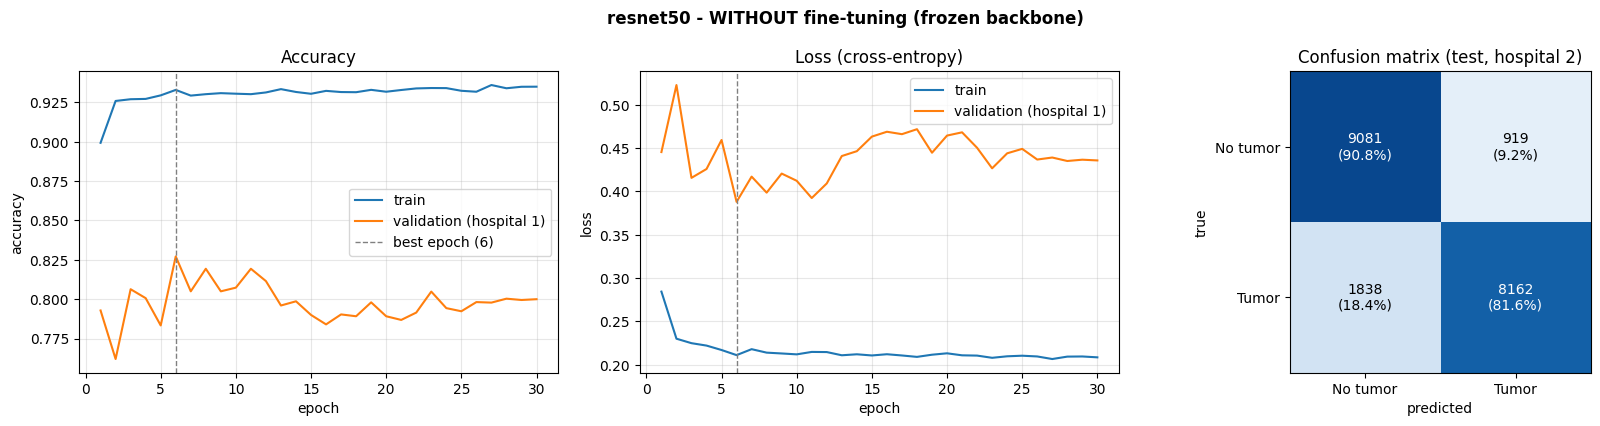

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.8317    0.9081    0.8682     10000
       Tumor     0.8988    0.8162    0.8555     10000

    accuracy                         0.8621     20000
   macro avg     0.8652    0.8621    0.8619     20000
weighted avg     0.8652    0.8621    0.8619     20000

AUC 0.9359 | best epoch 6 | training time 3.1 min | testing time 4.38 s (4566 images/s)
[resnet50_finetune_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


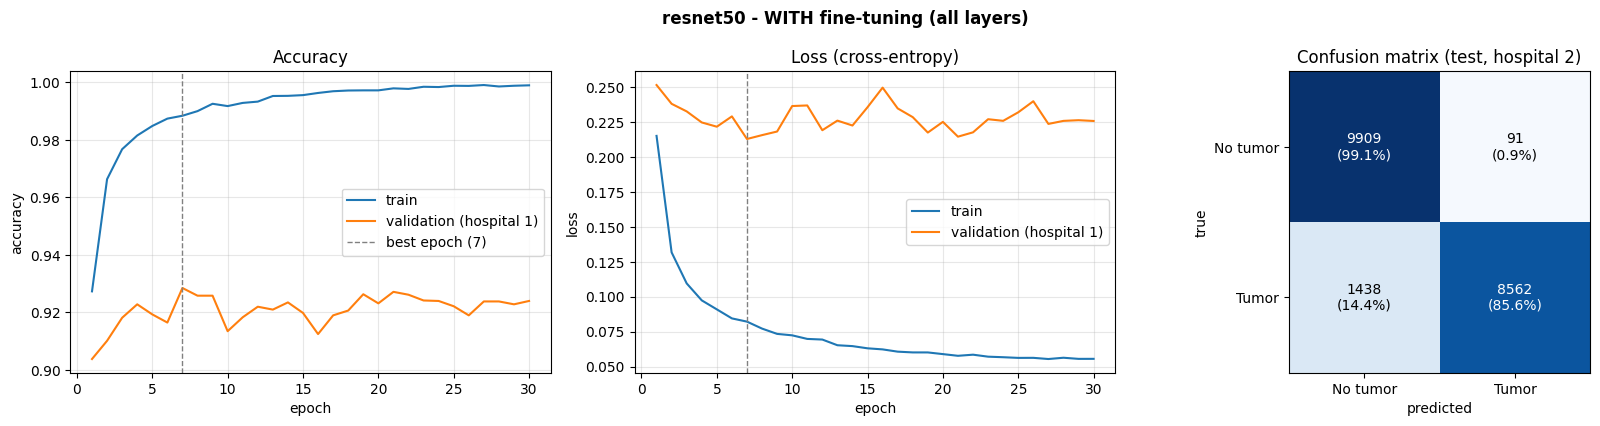

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.8733    0.9909    0.9284     10000
       Tumor     0.9895    0.8562    0.9180     10000

    accuracy                         0.9235     20000
   macro avg     0.9314    0.9235    0.9232     20000
weighted avg     0.9314    0.9235    0.9232     20000

AUC 0.9775 | best epoch 7 | training time 7.6 min | testing time 4.52 s (4426 images/s)


In [22]:
for mode in ["frozen", "finetune"]:
    all_results[("resnet50", mode)] = res = run_experiment("resnet50", mode)
    show_run(res)

#### 6.2 DenseNet-121

[densenet121_frozen_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


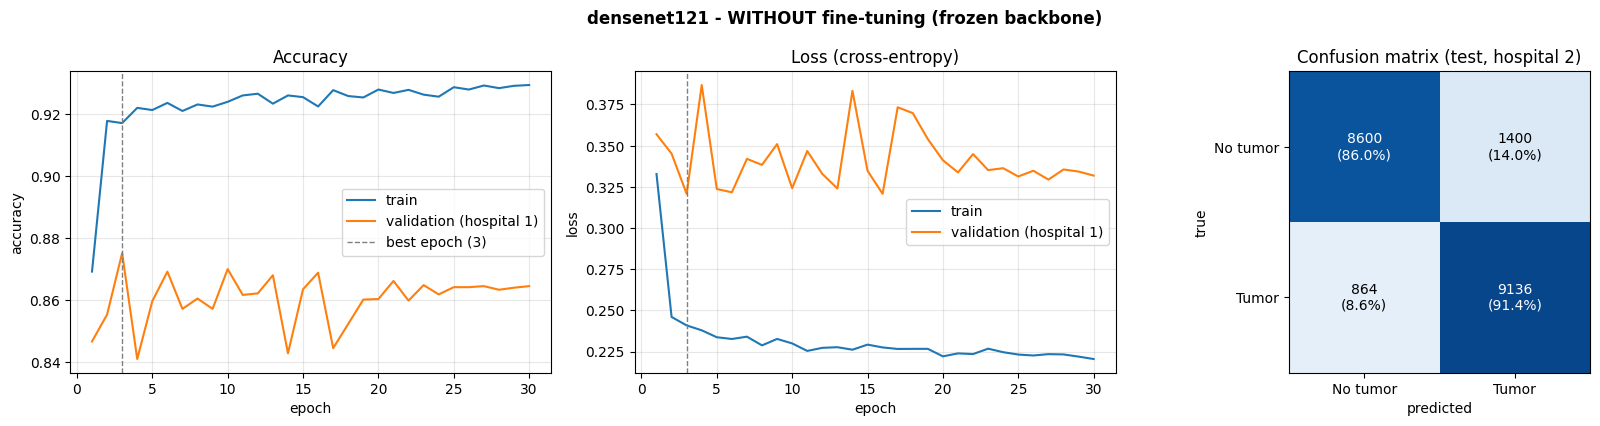

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.9087    0.8600    0.8837     10000
       Tumor     0.8671    0.9136    0.8898     10000

    accuracy                         0.8868     20000
   macro avg     0.8879    0.8868    0.8867     20000
weighted avg     0.8879    0.8868    0.8867     20000

AUC 0.9519 | best epoch 3 | training time 4.2 min | testing time 6.15 s (3251 images/s)
[densenet121_finetune_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


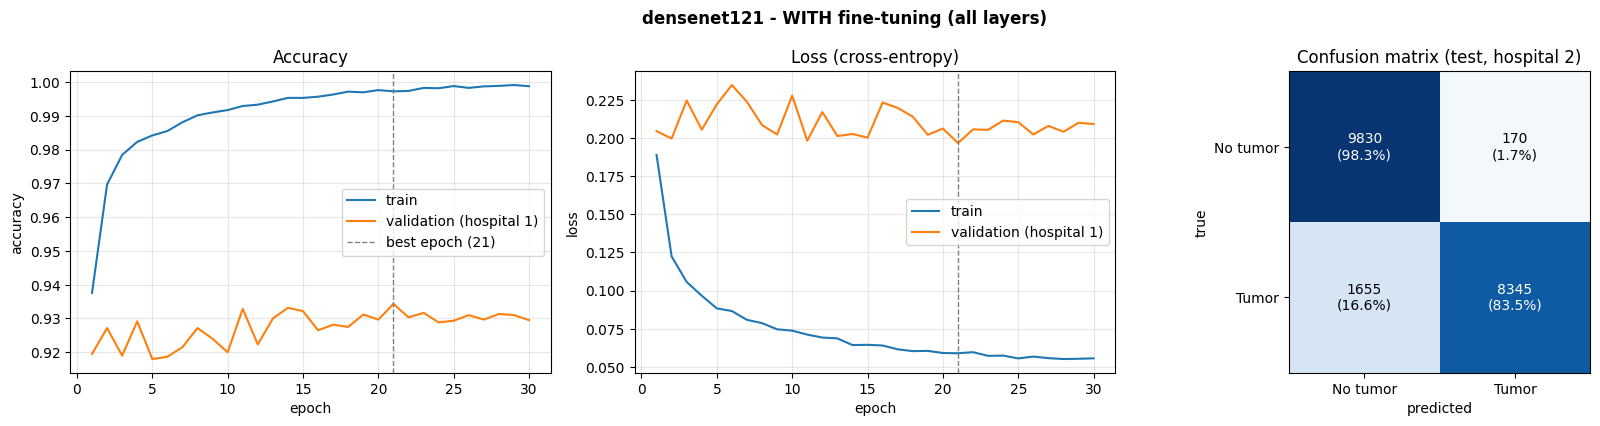

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.8559    0.9830    0.9151     10000
       Tumor     0.9800    0.8345    0.9014     10000

    accuracy                         0.9087     20000
   macro avg     0.9180    0.9087    0.9082     20000
weighted avg     0.9180    0.9087    0.9082     20000

AUC 0.9694 | best epoch 21 | training time 9.8 min | testing time 6.10 s (3276 images/s)


In [23]:
for mode in ["frozen", "finetune"]:
    all_results[("densenet121", mode)] = res = run_experiment("densenet121", mode)
    show_run(res)

#### 6.3 EfficientNet-B0

[efficientnet_b0_frozen_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


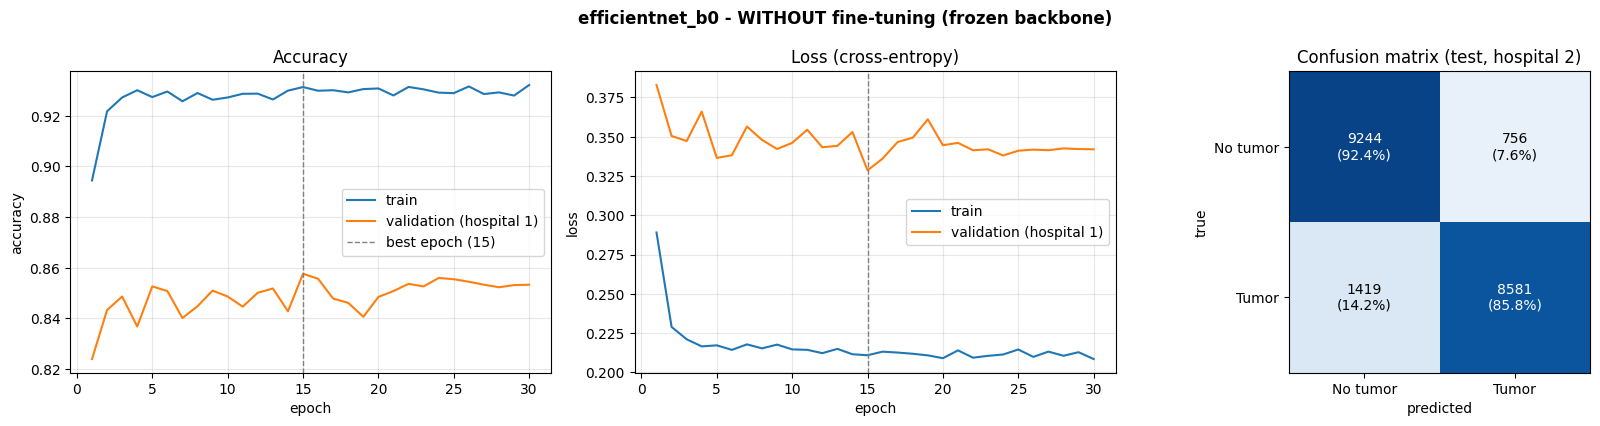

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.8669    0.9244    0.8947     10000
       Tumor     0.9190    0.8581    0.8875     10000

    accuracy                         0.8912     20000
   macro avg     0.8930    0.8912    0.8911     20000
weighted avg     0.8930    0.8912    0.8911     20000

AUC 0.9561 | best epoch 15 | training time 1.9 min | testing time 2.64 s (7570 images/s)
[efficientnet_b0_finetune_e30_tr20000_va6000_te20000_s96_seed42] found saved result, skipping training.


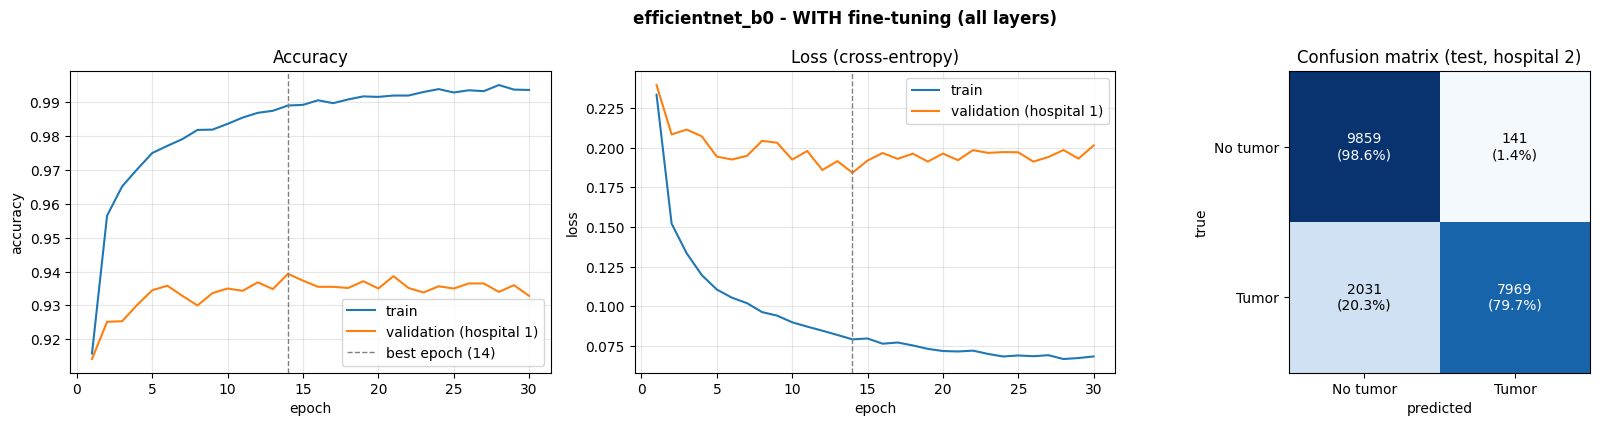

Classification report - test hospital 2 (20000 patches)
              precision    recall  f1-score   support

    No tumor     0.8292    0.9859    0.9008     10000
       Tumor     0.9826    0.7969    0.8801     10000

    accuracy                         0.8914     20000
   macro avg     0.9059    0.8914    0.8904     20000
weighted avg     0.9059    0.8914    0.8904     20000

AUC 0.9625 | best epoch 14 | training time 5.4 min | testing time 2.45 s (8158 images/s)


In [24]:
for mode in ["frozen", "finetune"]:
    all_results[("efficientnet_b0", mode)] = res = run_experiment("efficientnet_b0", mode)
    show_run(res)

### 7. Comparison of all models and modes

In [25]:
NICE = {"resnet50": "ResNet-50", "densenet121": "DenseNet-121", "efficientnet_b0": "EfficientNet-B0"}
rows = []
for (name, mode), r in all_results.items():
    rows.append({
        "Model": NICE[name], "Mode": "Fine-tuned" if mode == "finetune" else "Frozen (no fine-tuning)",
        "Trainable params (M)": round(r["params_trainable"] / 1e6, 2), "Best epoch": r["best_epoch"],
        "Train acc": r["train_acc_at_best"], "Val acc (hosp. 1)": r["val_acc"],
        "Test acc (hosp. 2)": r["test_acc"], "Precision (macro)": r["test_precision"],
        "Recall (macro)": r["test_recall"], "F1 (macro)": r["test_f1"], "AUC": r["test_auc"],
        "Train time (min)": r["train_time_s"] / 60, "Test time (s)": r["test_time_s"],
    })
results_df = pd.DataFrame(rows)
results_df.to_csv(f"{WORK_DIR}/submission2_results.csv", index=False)
display(results_df.style.format({c: "{:.4f}" for c in ["Train acc", "Val acc (hosp. 1)", "Test acc (hosp. 2)",
        "Precision (macro)", "Recall (macro)", "F1 (macro)", "AUC"]} | {"Train time (min)": "{:.1f}", "Test time (s)": "{:.2f}"})
        .background_gradient(subset=["Test acc (hosp. 2)", "F1 (macro)"], cmap="Greens"))

,Model,Mode,Trainable params (M),Best epoch,Train acc,Val acc (hosp. 1),Test acc (hosp. 2),Precision (macro),Recall (macro),F1 (macro),AUC,Train time (min),Test time (s)
0,ResNet-50,Frozen (no fine-tuning),0.000000,6,0.9329,0.8272,0.8621,0.8652,0.8621,0.8619,0.9359,3.1,4.38
1,ResNet-50,Fine-tuned,23.510000,7,0.9883,0.9285,0.9235,0.9314,0.9235,0.9232,0.9775,7.6,4.52
2,DenseNet-121,Frozen (no fine-tuning),0.000000,3,0.9171,0.8752,0.8868,0.8879,0.8868,0.8867,0.9519,4.2,6.15
3,DenseNet-121,Fine-tuned,6.960000,21,0.9972,0.9343,0.9087,0.9180,0.9087,0.9082,0.9694,9.8,6.10
4,EfficientNet-B0,Frozen (no fine-tuning),0.000000,15,0.9313,0.8577,0.8912,0.8930,0.8912,0.8911,0.9561,1.9,2.64
5,EfficientNet-B0,Fine-tuned,4.010000,14,0.9891,0.9393,0.8914,0.9059,0.8914,0.8904,0.9625,5.4,2.45


In [19]:

pc = []
for (name, mode), r in all_results.items():
    for c in CLASS_NAMES:
        d = r["report_dict"][c]
        pc.append({"Model": NICE[name], "Mode": "Fine-tuned" if mode == "finetune" else "Frozen",
                   "Class": c, "Precision": d["precision"], "Recall": d["recall"], "F1": d["f1-score"], "Support": int(d["support"])})
display(pd.DataFrame(pc).style.format({"Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}))

,Model,Mode,Class,Precision,Recall,F1,Support
0,ResNet-50,Frozen,No tumor,0.8317,0.9081,0.8682,10000
1,ResNet-50,Frozen,Tumor,0.8988,0.8162,0.8555,10000
2,ResNet-50,Fine-tuned,No tumor,0.8733,0.9909,0.9284,10000
3,ResNet-50,Fine-tuned,Tumor,0.9895,0.8562,0.9180,10000
4,DenseNet-121,Frozen,No tumor,0.9087,0.8600,0.8837,10000
5,DenseNet-121,Frozen,Tumor,0.8671,0.9136,0.8898,10000
6,DenseNet-121,Fine-tuned,No tumor,0.8559,0.9830,0.9151,10000
7,DenseNet-121,Fine-tuned,Tumor,0.9800,0.8345,0.9014,10000
8,EfficientNet-B0,Frozen,No tumor,0.8669,0.9244,0.8947,10000
9,EfficientNet-B0,Frozen,Tumor,0.9190,0.8581,0.8875,10000


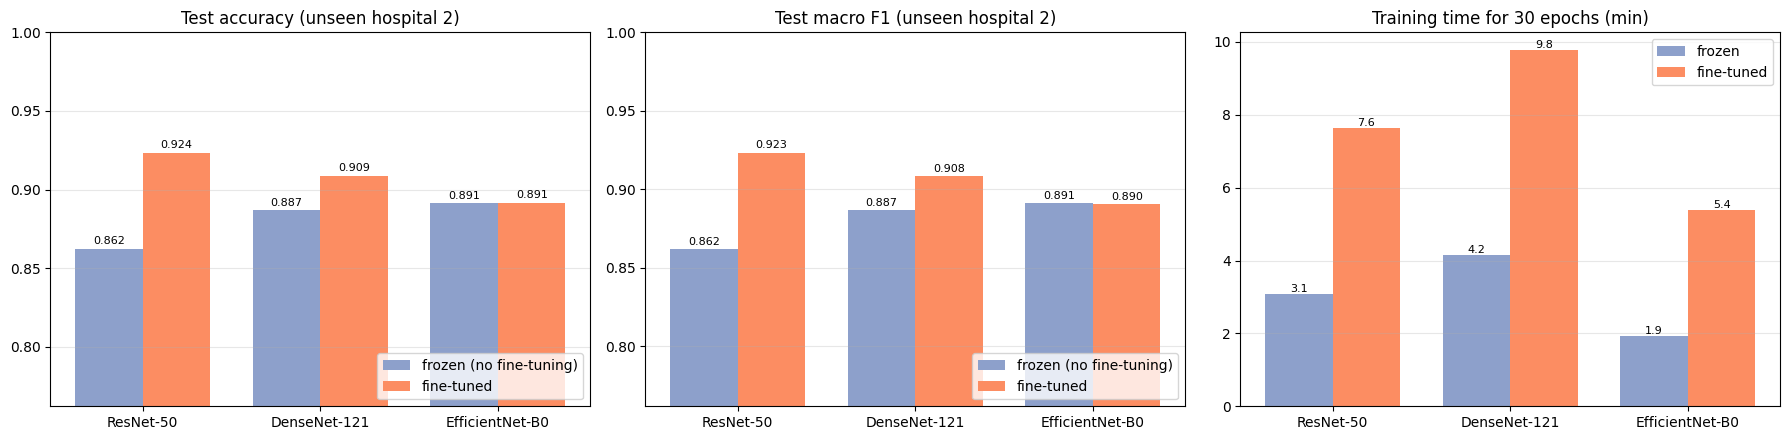

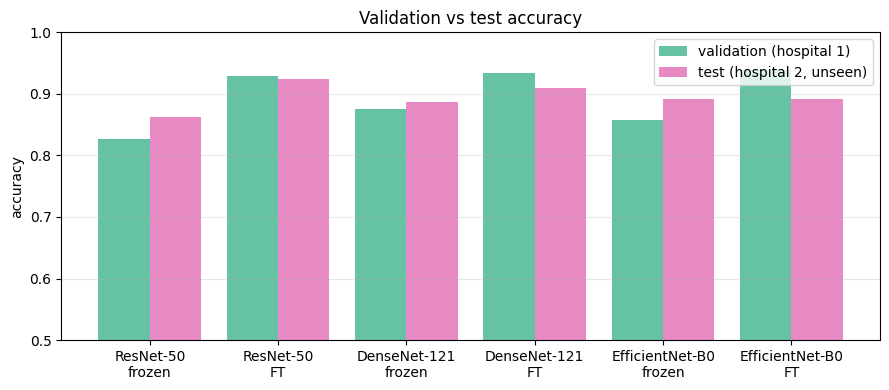

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
labels = [NICE[m] for m in MODELS]; x = np.arange(len(MODELS)); w = 0.38
def vals(key, mode): return [all_results[(m, mode)][key] for m in MODELS]

for a, key, title in [(ax[0], "test_acc", "Test accuracy (unseen hospital 2)"), (ax[1], "test_f1", "Test macro F1 (unseen hospital 2)")]:
    b1 = a.bar(x - w/2, vals(key, "frozen"), w, label="frozen (no fine-tuning)", color="#8da0cb")
    b2 = a.bar(x + w/2, vals(key, "finetune"), w, label="fine-tuned", color="#fc8d62")
    for bars in (b1, b2):
        for b in bars: a.text(b.get_x() + b.get_width()/2, b.get_height() + .003, f"{b.get_height():.3f}", ha="center", fontsize=8)
    lo = min(vals(key, "frozen") + vals(key, "finetune"))
    a.set(title=title, ylim=(max(0, lo - 0.1), 1.0), xticks=x, xticklabels=labels); a.legend(loc="lower right"); a.grid(axis="y", alpha=.3)

tt = ax[2]
b1 = tt.bar(x - w/2, [v / 60 for v in vals("train_time_s", "frozen")], w, color="#8da0cb", label="frozen")
b2 = tt.bar(x + w/2, [v / 60 for v in vals("train_time_s", "finetune")], w, color="#fc8d62", label="fine-tuned")
for bars in (b1, b2):
    for b in bars: tt.text(b.get_x() + b.get_width()/2, b.get_height(), f"{b.get_height():.1f}", ha="center", va="bottom", fontsize=8)
tt.set(title=f"Training time for {EPOCHS} epochs (min)", xticks=x, xticklabels=labels); tt.legend(); tt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()


fig, a = plt.subplots(figsize=(9, 4))
keys = [(m, md_) for m in MODELS for md_ in ("frozen", "finetune")]
xx = np.arange(len(keys))
a.bar(xx - .2, [all_results[k]["val_acc"] for k in keys], .4, label="validation (hospital 1)", color="#66c2a5")
a.bar(xx + .2, [all_results[k]["test_acc"] for k in keys], .4, label="test (hospital 2, unseen)", color="#e78ac3")
a.set(xticks=xx, xticklabels=[f"{NICE[m]}\n{'FT' if md_=='finetune' else 'frozen'}" for m, md_ in keys],
      ylabel="accuracy", title="Validation vs test accuracy"); a.set_ylim(0.5, 1.0); a.legend(); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

### 8. Over/underfitting diagnostics and findings

The roadmap requires fixing overfitting or underfitting. The cell below checks every run with simple rules and prints the result, so the conclusions always match the numbers above:

- **Overfitting** if train accuracy exceeds validation accuracy by more than 10 points at the best epoch, or if validation loss at the last epoch is more than 15% above its minimum.
- **Underfitting** if train accuracy at the best epoch is below 85%.
- **Domain-shift gap** if validation (hospital 1) accuracy is more than 5 points above test (hospital 2) accuracy.

In [21]:
print(f"{'run':36s} {'train':>6s} {'val':>6s} {'test':>6s} | gap(train-val) gap(val-test) | verdict")
for (name, mode), r in all_results.items():
    h = r["history"]
    tr, va, te = r["train_acc_at_best"], r["val_acc"], r["test_acc"]
    vmin, vlast = min(h["val_loss"]), h["val_loss"][-1]
    flags = []
    if tr - va > 0.10 or vlast > 1.15 * vmin: flags.append("OVERFITTING")
    if tr < 0.85: flags.append("underfitting")
    if va - te > 0.05: flags.append("domain-shift gap")
    print(f"{NICE[name] + ' / ' + mode:36s} {tr:6.3f} {va:6.3f} {te:6.3f} | {tr-va:+13.3f} {va-te:+12.3f} | {', '.join(flags) or 'ok'}")

best_key = max(all_results, key=lambda k: all_results[k]["test_f1"])
fast_key = min(all_results, key=lambda k: all_results[k]["train_time_s"])
print(f"\nBest test macro-F1: {NICE[best_key[0]]} ({best_key[1]}) = {all_results[best_key]['test_f1']:.4f} "
      f"(accuracy {all_results[best_key]['test_acc']:.4f}, AUC {all_results[best_key]['test_auc']:.4f})")
print(f"Fastest to train:   {NICE[fast_key[0]]} ({fast_key[1]}) = {all_results[fast_key]['train_time_s']/60:.1f} min")
print("\nEffect of fine-tuning on test accuracy:")
for m in MODELS:
    a, b = all_results[(m, "frozen")]["test_acc"], all_results[(m, "finetune")]["test_acc"]
    print(f"  {NICE[m]:16s} frozen {a:.4f} -> fine-tuned {b:.4f}  ({b-a:+.4f})")

run                                   train    val   test | gap(train-val) gap(val-test) | verdict
ResNet-50 / frozen                    0.933  0.827  0.862 |        +0.106       -0.035 | OVERFITTING
ResNet-50 / finetune                  0.988  0.928  0.924 |        +0.060       +0.005 | ok
DenseNet-121 / frozen                 0.917  0.875  0.887 |        +0.042       -0.012 | ok
DenseNet-121 / finetune               0.997  0.934  0.909 |        +0.063       +0.026 | ok
EfficientNet-B0 / frozen              0.931  0.858  0.891 |        +0.074       -0.034 | ok
EfficientNet-B0 / finetune            0.989  0.939  0.891 |        +0.050       +0.048 | ok

Best test macro-F1: ResNet-50 (finetune) = 0.9232 (accuracy 0.9235, AUC 0.9775)
Fastest to train:   EfficientNet-B0 (frozen) = 1.9 min

Effect of fine-tuning on test accuracy:
  ResNet-50        frozen 0.8621 -> fine-tuned 0.9235  (+0.0614)
  DenseNet-121     frozen 0.8868 -> fine-tuned 0.9087  (+0.0219)
  EfficientNet-B0  frozen 0.8912 

### 9. Findings

- **Best result:** ResNet-50 with fine-tuning: 92.35% test accuracy, macro-F1 0.9232, AUC 0.9775 on the unseen hospital 2 (7.6 min training).
- **Fine-tuning vs frozen backbone (test accuracy):** ResNet-50 +6.14 points (86.21% to 92.35%), DenseNet-121 +2.19 points (88.68% to 90.87%), EfficientNet-B0 +0.02 points (89.12% to 89.14%). Fine-tuning took 2.3x to 2.8x longer to train.
- **Error pattern:** all fine-tuned models are very precise when they flag tumor (precision 0.98 to 0.99) but miss 14% to 20% of tumor patches on hospital 2 (tumor recall 0.797 to 0.856); frozen models are more balanced.
- **Validation vs test:** fine-tuned models score 0.5 to 4.8 points higher on validation hospital 1 than on test hospital 2; frozen models score 1.2 to 3.5 points lower. The domain shift between hospitals makes best-epoch selection on one hospital an imperfect guide for another.
- **Overfitting / underfitting:** only ResNet-50 frozen met the overfitting rule (validation loss rises after epoch 6); restoring the best-validation epoch keeps this out of the test results. No run underfits.
- **Limitations:** stratified subset (20,000 train / 6,000 validation / 20,000 test patches), one random seed, one unseen test hospital; differences of about one point should not be over-interpreted.

**Reference:** Koh et al., "WILDS: A Benchmark of in-the-Wild Distribution Shifts", ICML 2021 (https://arxiv.org/abs/2012.07421).